# Statistical Analysis & Distribution Fitting

Analysis of claim frequency overdispersion, parametric severity distribution fitting (Gamma, Log-Normal, Weibull), hypothesis testing across categorical rating factors, and feature multicollinearity checks.

In [1]:
import os
import sys
import numpy as np
import pandas as pd
import scipy.stats as stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.outliers_influence import variance_inflation_factor
import matplotlib.pyplot as plt
import seaborn as sns

sys.path.append(os.path.abspath(".."))
from src.statistical import compute_dispersion, fit_severity_distributions, compute_vif

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["font.size"] = 10

## 1. Data Load

In [2]:
df = pd.read_parquet("../data/processed/abt_motor_portfolio.parquet")
print(f"Loaded dataset: {df.shape[0]:,} rows, {df.shape[1]} columns")
df.head()

Loaded dataset: 678,013 rows, 22 columns


,IDpol,ClaimNb,ClaimNb_Capped,Exposure,Exposure_Capped,LogExposure,SevRecordCount,TotalClaimAmount,AvgClaimSeverity,PurePremium,...,Area,VehPower,VehAge,DrivAge,BonusMalus,VehBrand,VehGas,Density,LogDensity,Region
0,5048069,0,0,0.03,0.03,-3.506558,0,0.0,0.0,0.0,...,B,7,1,23,76,B12,Diesel,52,3.951244,R83
1,5048071,0,0,0.14,0.14,-1.966113,0,0.0,0.0,0.0,...,B,9,5,23,76,B12,Regular,52,3.951244,R83
2,5048073,0,0,0.67,0.67,-0.400478,0,0.0,0.0,0.0,...,B,7,1,23,76,B12,Diesel,52,3.951244,R83
3,5048074,0,0,0.13,0.13,-2.040221,0,0.0,0.0,0.0,...,E,4,1,51,60,B12,Diesel,2715,7.906547,R93
4,5048078,0,0,0.86,0.86,-0.150823,0,0.0,0.0,0.0,...,E,4,1,51,75,B12,Diesel,2715,7.906547,R93


## 2. Claim Frequency & Dispersion Diagnostics

In [3]:
claim_counts = df["ClaimNb"].value_counts().sort_index()
claim_pct = df["ClaimNb"].value_counts(normalize=True).sort_index() * 100

pd.DataFrame({
    "Claim Count": claim_counts.index,
    "Policies": claim_counts.values,
    "Percentage (%)": claim_pct.values.round(3)
}).head(6)

,Claim Count,Policies,Percentage (%)
0,0,643953,94.976
1,1,32178,4.746
2,2,1784,0.263
3,3,82,0.012
4,4,7,0.001
5,5,2,0.000


In [4]:
disp_results = compute_dispersion(df)
print(f"Log-Likelihood: {disp_results['llf']:,.2f}")
print(f"Pearson Chi-Square: {disp_results['pearson_chi2']:,.2f}")
print(f"Dispersion Parameter (phi): {disp_results['dispersion_phi']:.4f}")

Log-Likelihood: -146,894.53
Pearson Chi-Square: 1,976,881.17
Dispersion Parameter (phi): 2.9157


## 3. Severity Distribution Fitting

In [5]:
claims_data = df[(df["HasClaim"] == 1) & (df["IsLargeLoss"] == 0)]["AvgClaimSeverity"].dropna()
claims_data = claims_data[claims_data > 0]

print(f"Positive attritional claims: {len(claims_data):,}")
print(f"Mean: €{claims_data.mean():,.2f} | Median: €{claims_data.median():,.2f} | Std: €{claims_data.std():,.2f}")

fit_results = fit_severity_distributions(claims_data)
fit_results

Positive attritional claims: 24,902
Mean: €1,691.72 | Median: €1,172.00 | Std: €3,851.68


,Distribution,Log-Likelihood,AIC,BIC,KS-Stat,p-value
1,Log-Normal,-208061.834674,416127.669348,416143.914755,0.230989,0.0
2,Weibull,-209602.516240,419209.032481,419225.277887,0.201912,0.0
0,Gamma,-210009.208025,420022.416050,420038.661457,0.235503,0.0


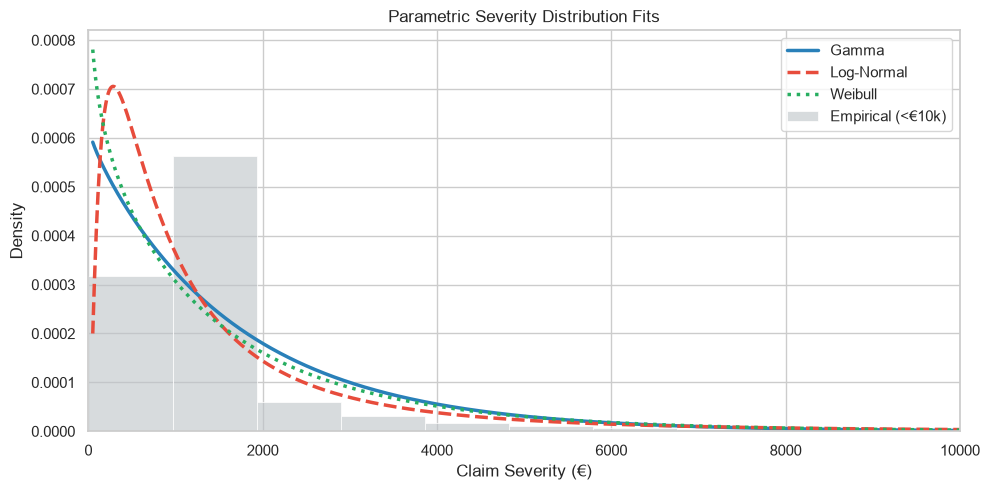

In [6]:
# Fit parametric curves for overlay plot
g_shape, _, g_scale = stats.gamma.fit(claims_data, floc=0)
ln_s, _, ln_scale = stats.lognorm.fit(claims_data, floc=0)
wb_c, _, wb_scale = stats.weibull_min.fit(claims_data, floc=0)

x_grid = np.linspace(50, 10000, 1000)

plt.figure(figsize=(10, 5))
sns.histplot(claims_data, bins=100, stat="density", color="#bdc3c7", label="Empirical (<€10k)", alpha=0.6)
plt.plot(x_grid, stats.gamma.pdf(x_grid, g_shape, 0, g_scale), color="#2980b9", lw=2.5, label="Gamma")
plt.plot(x_grid, stats.lognorm.pdf(x_grid, ln_s, 0, ln_scale), color="#e74c3c", lw=2.5, linestyle="--", label="Log-Normal")
plt.plot(x_grid, stats.weibull_min.pdf(x_grid, wb_c, 0, wb_scale), color="#27ae60", lw=2.5, linestyle=":", label="Weibull")

plt.xlim(0, 10000)
plt.title("Parametric Severity Distribution Fits")
plt.xlabel("Claim Severity (€)")
plt.ylabel("Density")
plt.legend()
plt.tight_layout()
plt.show()

## 4. Rating Factor Significance Tests

In [7]:
# Fuel Type (VehGas) test
model_gas = smf.glm("ClaimNb ~ C(VehGas)", data=df, family=sm.families.Poisson(), offset=df["LogExposure"]).fit()
print(model_gas.summary().tables[1])
print(f"\nVehGas Wald p-value: {model_gas.pvalues.iloc[1]:.4e}")

                           coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------
Intercept               -2.3270      0.008   -300.241      0.000      -2.342      -2.312
C(VehGas)[T.Regular]     0.0598      0.011      5.662      0.000       0.039       0.080

VehGas Wald p-value: 1.4956e-08


In [8]:
# Urban Area (Area) test
model_area = smf.glm("ClaimNb ~ C(Area)", data=df, family=sm.families.Poisson(), offset=df["LogExposure"]).fit()
print(model_area.summary().tables[1])

lrt_area = model_area.null_deviance - model_area.deviance
df_diff = int(model_area.df_model)
p_val_area = stats.chi2.sf(lrt_area, df=df_diff)
print(f"\nDeviance Drop: {lrt_area:.2f} (df={df_diff}), p-value = {p_val_area:.4e}")

                   coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------
Intercept       -2.5045      0.014   -178.206      0.000      -2.532      -2.477
C(Area)[T.B]     0.0782      0.021      3.645      0.000       0.036       0.120
C(Area)[T.C]     0.1462      0.017      8.460      0.000       0.112       0.180
C(Area)[T.D]     0.2911      0.018     16.371      0.000       0.256       0.326
C(Area)[T.E]     0.4037      0.018     22.372      0.000       0.368       0.439
C(Area)[T.F]     0.5326      0.033     16.193      0.000       0.468       0.597

Deviance Drop: 784.54 (df=5), p-value = 2.5552e-167


## 5. Multicollinearity Analysis

In [9]:
numeric_features = ["VehPower", "VehAge", "DrivAge", "BonusMalus", "LogDensity"]
vif_df = compute_vif(df, numeric_features)
vif_df

,Feature,VIF
0,BonusMalus,1.331506
1,DrivAge,1.300429
2,LogDensity,1.030021
3,VehAge,1.020418
4,VehPower,1.006065


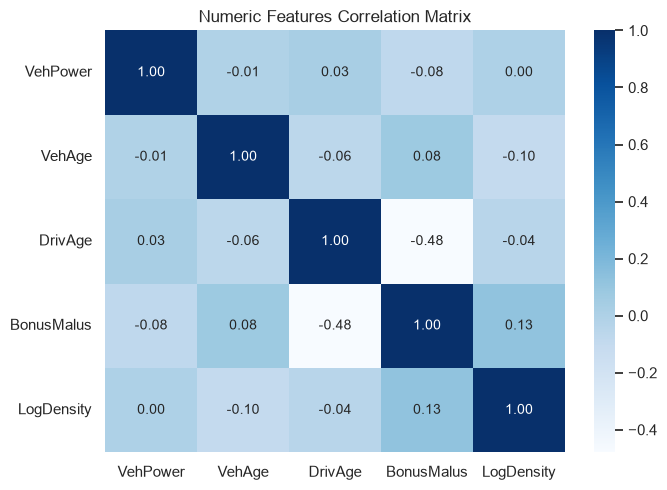

In [10]:
plt.figure(figsize=(7, 5))
sns.heatmap(df[numeric_features].corr(), annot=True, cmap="Blues", fmt=".2f")
plt.title("Numeric Features Correlation Matrix")
plt.tight_layout()
plt.show()